# Importancia de los canales

El sistema acepta 12 combinaciones de canales: Fpz-Cz, Pz-Oz o los dos, con o sin EOG y con o sin EMG. La pregunta de este notebook es **cuánto aporta cada canal** a la predicción.

La respuesta sale de comparar el sistema **con y sin** ese canal. Por ejemplo, para el EOG se compara "solo Fpz-Cz" con "Fpz-Cz + EOG", "solo Pz-Oz" con "Pz-Oz + EOG", y así con todas las parejas que solo se diferencian en el EOG. El promedio de esas diferencias es lo que aporta el canal.

No se entrena nada: se usan las predicciones que ya dejaron los notebooks de entrenamiento, del XGBoost (modelo A), de la red (modelo B) y del sistema completo (meta-modelo), en las 12 combinaciones.

El notebook se organiza así:

1. **Librerías**
2. **Rutas y parámetros**
3. **Predicciones:** lectura y F1 macro de cada combinación.
4. **Cómo se mide la importancia:** las parejas de combinaciones.
5. **Validación cruzada:** los 62 sujetos de desarrollo.
6. **Test:** los 16 sujetos de test, con intervalos de confianza por bootstrap.
7. **Por estadio:** qué estadio mejora con cada canal.
8. **Conclusiones**

## 1. Librerías

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 2. Rutas y parámetros

Las predicciones están en `data/procesados/`:
- **A:** `modelo_a_xgboost_100_features/folds/`, un archivo por fold y uno del modelo final (`final.npz`), que predice el test;
- **B:** `modelo_b_red/predicciones/`, con la misma organización;
- **sistema:** `meta_modelo/predicciones.npz`.

Las predicciones de la CV son **fuera de fold**: cada sujeto lo predice un modelo que no lo vio al entrenar.

In [2]:
# Raíz del repositorio: la carpeta que tiene particiones.json
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "particiones.json").exists())
PROCESADOS = RAIZ / "data" / "procesados"
PRED_A = PROCESADOS / "modelo_a_xgboost_100_features" / "folds"
PRED_B = PROCESADOS / "modelo_b_red" / "predicciones"
PRED_META = PROCESADOS / "meta_modelo" / "predicciones.npz"

SEED = 42
N_BOOT = 2000
ESTADIOS = ["W", "N1", "N2", "N3", "REM"]
K = len(ESTADIOS)
CANALES = ["fpz", "pz", "eog", "emg"]
NOMBRE = {"fpz": "Fpz-Cz", "pz": "Pz-Oz", "eog": "EOG", "emg": "EMG"}

particion = json.loads((RAIZ / "particiones.json").read_text())
CONFIGS = {c: frozenset(v) for c, v in particion["combinaciones"].items()}
COMBOS = list(CONFIGS)
FOLDS = [f"fold_{f['fold']}" for f in particion["folds"]]

## 3. Predicciones

Leemos las tres. Cada una queda como *combinación → noche → (etiquetas, probabilidades)*. Las predicciones de los 5 folds juntas forman la CV, y las del modelo final, el test.

In [3]:
# Funciones para leer las predicciones de A, B y del sistema
def leer_a(nombre):
    z = np.load(PRED_A / f"{nombre}.npz")
    out = {}
    for k in z.files:
        c, n, tipo = k.split("__")
        if tipo == "y":
            out.setdefault(c, {})[n] = (z[k], z[f"{c}__{n}__pred"])
    return out


def leer_b(nombre):
    z = np.load(PRED_B / f"{nombre}.npz")
    out = {}
    for k in z.files:
        c, n = k.split("__")
        if c in CONFIGS:
            out.setdefault(c, {})[n] = (z[f"y__{n}"], z[k])
    return out


def leer_sistema():
    z = np.load(PRED_META)
    out = {"oof": {}, "test": {}}
    for k in z.files:
        parte, c, n, tipo = k.split("__")
        if tipo == "y":
            out[parte].setdefault(c, {})[n] = (z[k], z[f"{parte}__{c}__{n}__pred"])
    return out


def juntar(leer):
    out = {"oof": {c: {} for c in CONFIGS}, "test": {c: {} for c in CONFIGS}}
    for nombre in FOLDS + ["final"]:
        parte = "test" if nombre == "final" else "oof"
        for c, d in leer(nombre).items():
            out[parte][c].update(d)
    return out


PRED = {"XGBoost (A)": juntar(leer_a), "Red (B)": juntar(leer_b), "Sistema": leer_sistema()}
MODELOS = list(PRED)
for m, P in PRED.items():
    print(f"{m}: {len(P['oof']['fpz'])} noches de CV y {len(P['test']['fpz'])} de test, en {len(P['oof'])} combinaciones")

XGBoost (A): 121 noches de CV y 32 de test, en 12 combinaciones
Red (B): 121 noches de CV y 32 de test, en 12 combinaciones
Sistema: 121 noches de CV y 32 de test, en 12 combinaciones


### Matrices de confusión por sujeto

Todas las métricas salen de matrices de confusión. Guardamos una por modelo, combinación y **sujeto** (sus dos noches juntas), porque el bootstrap de la sección 6 remuestrea sujetos. Solo cuentan las épocas con etiqueta.

In [4]:
# Matriz de confusión de cada sujeto: (combinación, sujeto, real, predicho)
def confusiones(preds):
    sujetos = sorted({int(n[3:5]) for n in preds[COMBOS[0]]})
    cm = np.zeros((len(COMBOS), len(sujetos), K, K), dtype=np.int64)
    for i, c in enumerate(COMBOS):
        for n, (y, p) in preds[c].items():
            v = y >= 0
            cm[i, sujetos.index(int(n[3:5]))] += np.bincount(y[v] * K + p[v].argmax(1), minlength=K * K).reshape(K, K)
    return cm


CM = {m: {parte: confusiones(PRED[m][parte]) for parte in ("oof", "test")} for m in MODELOS}
print("sujetos de CV:", CM["Sistema"]["oof"].shape[1], "· sujetos de test:", CM["Sistema"]["test"].shape[1])

sujetos de CV: 62 · sujetos de test: 16


El F1 de cada estadio sale de la matriz de confusión, y el F1 macro (MF1) es su promedio. La función trabaja con muchas matrices a la vez, lo que hace rápido el bootstrap.

In [5]:
# F1 por estadio a partir de matrices de confusión (las últimas dos dimensiones)
def f1_por_estadio(cm):
    tp = np.diagonal(cm, axis1=-2, axis2=-1)
    total = cm.sum(-1) + cm.sum(-2)
    return np.divide(2 * tp, total, out=np.zeros(tp.shape), where=total > 0)


F1 = {m: {parte: f1_por_estadio(CM[m][parte].sum(1)) for parte in ("oof", "test")} for m in MODELOS}

El punto de partida: el MF1 de cada combinación, en la CV y en el test. Son las mismas cifras de los notebooks de entrenamiento.

In [6]:
# MF1 por combinación
pd.concat({parte: pd.DataFrame({m: F1[m][key].mean(1) for m in MODELOS}, index=COMBOS)
           for parte, key in (("CV", "oof"), ("Test", "test"))}, axis=1).style.format(precision=3)

## 4. Cómo se mide la importancia

Un canal se compara en todas las **parejas** de combinaciones que solo se diferencian en ese canal. Las parejas tienen que ser combinaciones válidas, con al menos un EEG:
- **EOG** y **EMG:** 6 parejas cada uno, una por cada combinación de EEG y del otro canal;
- **Fpz-Cz:** 4 parejas, agregándolo donde ya está Pz-Oz (sin él quedaría una combinación sin EEG);
- **Pz-Oz:** 4 parejas, agregándolo donde ya está Fpz-Cz.

El **aporte** del canal es el promedio de las diferencias de MF1 (con el canal − sin él).

In [7]:
# Parejas de combinaciones que solo se diferencian en un canal
def parejas(canal):
    return [(c, d) for c, s in CONFIGS.items() for d, t in CONFIGS.items() if canal not in s and t == s | {canal}]


for canal in CANALES:
    print(f"{NOMBRE[canal]:7s}", " · ".join(f"{c} → {d}" for c, d in parejas(canal)))

Fpz-Cz  pz → eeg2 · pz_eog → eeg2_eog · pz_emg → eeg2_emg · pz_eog_emg → eeg2_eog_emg
Pz-Oz   fpz → eeg2 · fpz_eog → eeg2_eog · fpz_emg → eeg2_emg · fpz_eog_emg → eeg2_eog_emg
EOG     fpz → fpz_eog · pz → pz_eog · eeg2 → eeg2_eog · fpz_emg → fpz_eog_emg · pz_emg → pz_eog_emg · eeg2_emg → eeg2_eog_emg
EMG     fpz → fpz_emg · pz → pz_emg · eeg2 → eeg2_emg · fpz_eog → fpz_eog_emg · pz_eog → pz_eog_emg · eeg2_eog → eeg2_eog_emg


Ejemplo con el EOG en el sistema, en la CV: el MF1 sin el EOG, con el EOG y la diferencia en cada pareja.

In [8]:
# Ejemplo: las 6 parejas del EOG en el sistema (CV)
mf1 = dict(zip(COMBOS, F1["Sistema"]["oof"].mean(1)))
ej = pd.DataFrame([{"sin EOG": c, "con EOG": d, "MF1 sin": mf1[c], "MF1 con": mf1[d], "diferencia": mf1[d] - mf1[c]}
                   for c, d in parejas("eog")])
print(f"aporte del EOG = promedio de las diferencias = {ej['diferencia'].mean():+.4f}")
ej.style.format(precision=4)

aporte del EOG = promedio de las diferencias = +0.0142


,sin EOG,con EOG,MF1 sin,MF1 con,diferencia
0,fpz,fpz_eog,0.7993,0.8077,0.0085
1,pz,pz_eog,0.7602,0.7878,0.0275
2,eeg2,eeg2_eog,0.8087,0.8167,0.0080
3,fpz_emg,fpz_eog_emg,0.8019,0.8103,0.0084
4,pz_emg,pz_eog_emg,0.7642,0.7895,0.0254
5,eeg2_emg,eeg2_eog_emg,0.8105,0.8176,0.0071


Las diferencias de MF1 se calculan con cualquier vector de F1; la función siguiente sirve tanto para las cifras puntuales como para las 2000 remuestras del bootstrap.

In [9]:
# Aporte de un canal: promedio de (F1 con el canal − F1 sin él) sobre sus parejas
IDX = {c: i for i, c in enumerate(COMBOS)}


def aporte(f1, canal):
    """f1: (..., combinación, estadio) -> (..., estadio)"""
    return np.mean([f1[..., IDX[d], :] - f1[..., IDX[c], :] for c, d in parejas(canal)], axis=0)

## 5. Validación cruzada

Los 62 sujetos de desarrollo, con predicciones fuera de fold. Para cada canal se muestra el aporte promedio y, entre paréntesis, la menor y la mayor diferencia entre sus parejas: si las dos tienen el mismo signo, el canal ayuda (o estorba) en todas las combinaciones.

In [10]:
# Aporte de cada canal al MF1 en la CV, con el rango entre parejas
def rango(f1, canal):
    mf1 = f1.mean(-1)
    return [mf1[IDX[d]] - mf1[IDX[c]] for c, d in parejas(canal)]


cv = pd.DataFrame({m: {NOMBRE[canal]: aporte(F1[m]["oof"], canal).mean() for canal in CANALES} for m in MODELOS})
pd.DataFrame({m: {NOMBRE[canal]: f"{aporte(F1[m]['oof'], canal).mean():+.3f} ({min(rango(F1[m]['oof'], canal)):+.3f} a {max(rango(F1[m]['oof'], canal)):+.3f})"
                  for canal in CANALES} for m in MODELOS})

,XGBoost (A),Red (B),Sistema
Fpz-Cz,+0.048 (+0.038 a +0.060),+0.032 (+0.020 a +0.045),+0.038 (+0.028 a +0.048)
Pz-Oz,+0.013 (+0.010 a +0.016),+0.012 (+0.008 a +0.017),+0.009 (+0.007 a +0.009)
EOG,+0.014 (+0.007 a +0.026),+0.016 (+0.005 a +0.033),+0.014 (+0.007 a +0.028)
EMG,+0.008 (+0.004 a +0.012),+0.001 (-0.002 a +0.005),+0.002 (+0.001 a +0.004)


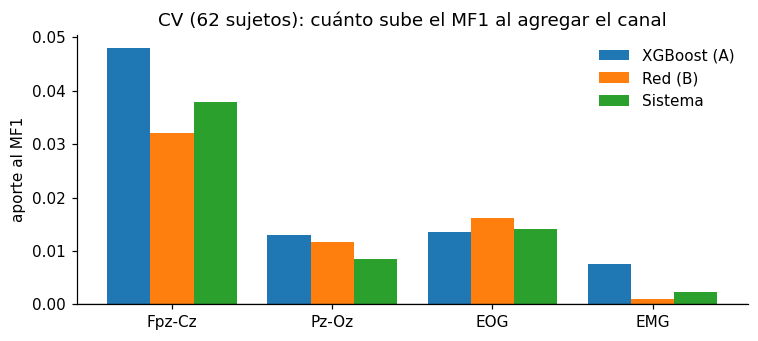

In [11]:
# Gráfica: aporte de cada canal al MF1 en la CV
fig, ax = plt.subplots(figsize=(7, 3.2))
ancho = 0.27
for j, m in enumerate(MODELOS):
    ax.bar(np.arange(len(CANALES)) + (j - 1) * ancho, cv[m].values, ancho, label=m)
ax.axhline(0, color="k", lw=0.8)
ax.set_xticks(range(len(CANALES)), [NOMBRE[c] for c in CANALES])
ax.set_ylabel("aporte al MF1")
ax.set_title("CV (62 sujetos): cuánto sube el MF1 al agregar el canal")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

## 6. Test

Los 16 sujetos de test, que no se usaron para ninguna decisión.

**Intervalos de confianza por bootstrap agrupado por sujeto.** Se remuestrean **personas** con reemplazo, 2000 veces (semilla 42), como en el notebook del meta-modelo: son las mismas remuestras. En cada remuestra se recalcula el aporte del canal, y el 2.5 % y el 97.5 % de los 2000 valores dan el intervalo. Como el sistema con y sin el canal se evalúa sobre las mismas personas, la diferencia es **pareada**: si el IC no cruza 0, el aporte es significativo.

In [12]:
# Remuestras de sujetos: cuántas veces entra cada sujeto en cada una
n_suj = CM["Sistema"]["test"].shape[1]
rng = np.random.default_rng(SEED)
VECES = np.stack([np.bincount(rng.integers(0, n_suj, n_suj), minlength=n_suj) for _ in range(N_BOOT)])
print(f"{N_BOOT} remuestras de {n_suj} sujetos · en la primera entran {np.count_nonzero(VECES[0])} sujetos distintos")

2000 remuestras de 16 sujetos · en la primera entran 10 sujetos distintos


In [13]:
# F1 de las 2000 remuestras: (remuestra, combinación, estadio)
F1_BOOT = {m: f1_por_estadio(np.einsum("bs,csij->bcij", VECES, CM[m]["test"])) for m in MODELOS}

In [14]:
# Aporte de cada canal al MF1 en el test, con su IC
filas = []
for canal in CANALES:
    for m in MODELOS:
        b = aporte(F1_BOOT[m], canal).mean(-1)
        lo, hi = np.percentile(b, [2.5, 97.5])
        filas.append({"canal": NOMBRE[canal], "modelo": m, "aporte": aporte(F1[m]["test"], canal).mean(),
                      "IC bajo": lo, "IC alto": hi, "significativo": "sí" if lo > 0 or hi < 0 else "no"})
test = pd.DataFrame(filas)
pd.DataFrame({m: {r.canal: f"{r.aporte:+.3f} [{r['IC bajo']:+.3f}, {r['IC alto']:+.3f}] {'*' if r.significativo == 'sí' else ''}"
                  for _, r in test[test.modelo == m].iterrows()} for m in MODELOS})

,XGBoost (A),Red (B),Sistema
Fpz-Cz,"+0.041 [+0.026, +0.060] *","+0.040 [+0.019, +0.070] *","+0.038 [+0.019, +0.069] *"
Pz-Oz,"+0.013 [-0.011, +0.030]","+0.011 [-0.002, +0.027]","+0.007 [-0.009, +0.022]"
EOG,"+0.012 [+0.006, +0.019] *","+0.012 [+0.002, +0.024] *","+0.009 [+0.003, +0.016] *"
EMG,"+0.012 [+0.007, +0.017] *","+0.001 [-0.005, +0.006]","+0.000 [-0.004, +0.004]"


Con asterisco, los aportes significativos.

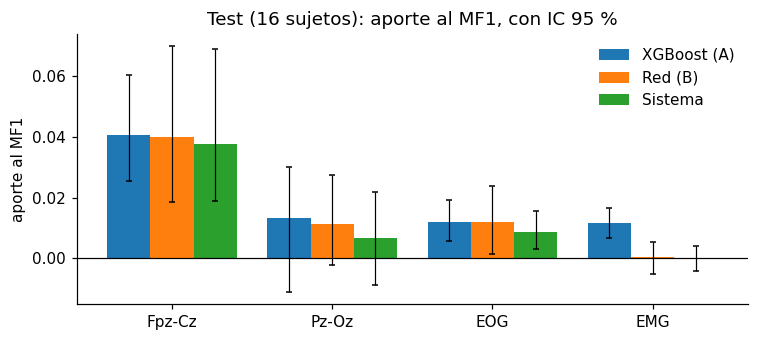

In [15]:
# Gráfica: aporte de cada canal en el test, con su IC
fig, ax = plt.subplots(figsize=(7, 3.2))
for j, m in enumerate(MODELOS):
    t = test[test.modelo == m].set_index("canal").loc[[NOMBRE[c] for c in CANALES]]
    x = np.arange(len(CANALES)) + (j - 1) * ancho
    ax.bar(x, t.aporte, ancho, label=m)
    ax.errorbar(x, t.aporte, yerr=[t.aporte - t["IC bajo"], t["IC alto"] - t.aporte], fmt="none", ecolor="k", lw=0.8, capsize=2)
ax.axhline(0, color="k", lw=0.8)
ax.set_xticks(range(len(CANALES)), [NOMBRE[c] for c in CANALES])
ax.set_ylabel("aporte al MF1")
ax.set_title("Test (16 sujetos): aporte al MF1, con IC 95 %")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

### CV y test juntos, en el sistema

In [16]:
# Resumen del sistema: aporte en la CV y en el test
ts = test[test.modelo == "Sistema"].set_index("canal")
pd.DataFrame({"CV": cv["Sistema"],
              "test": ts.aporte,
              "IC 95 % test": [f"[{ts.loc[c, 'IC bajo']:+.3f}, {ts.loc[c, 'IC alto']:+.3f}]" for c in cv.index],
              "significativo en test": ts.significativo}).loc[[NOMBRE[c] for c in CANALES]].style.format(precision=3)

,CV,test,IC 95 % test,significativo en test
Fpz-Cz,0.038,0.038,"[+0.019, +0.069]",sí
Pz-Oz,0.009,0.007,"[-0.009, +0.022]",no
EOG,0.014,0.009,"[+0.003, +0.016]",sí
EMG,0.002,0.000,"[-0.004, +0.004]",no


## 7. Por estadio

El mismo cálculo con el F1 de cada estadio en lugar del MF1 muestra **qué estadio** mejora con cada canal. Primero el sistema en la CV y en el test.

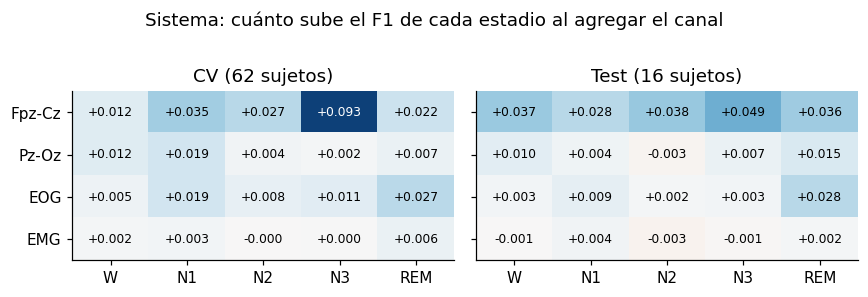

In [17]:
# Aporte de cada canal al F1 de cada estadio (sistema)
fig, axs = plt.subplots(1, 2, figsize=(8, 2.6), sharey=True)
for ax, (titulo, key) in zip(axs, (("CV (62 sujetos)", "oof"), ("Test (16 sujetos)", "test"))):
    a = np.array([aporte(F1["Sistema"][key], c) for c in CANALES])
    ax.imshow(a, cmap="RdBu", vmin=-0.1, vmax=0.1, aspect="auto")
    for i in range(len(CANALES)):
        for k in range(K):
            ax.text(k, i, f"{a[i, k]:+.3f}", ha="center", va="center", fontsize=8, color="w" if abs(a[i, k]) > 0.06 else "k")
    ax.set_xticks(range(K), ESTADIOS)
    ax.set_yticks(range(len(CANALES)), [NOMBRE[c] for c in CANALES])
    ax.set_title(titulo)
fig.suptitle("Sistema: cuánto sube el F1 de cada estadio al agregar el canal", y=1.02)
plt.tight_layout()
plt.show()

En el test, con su IC: cada celda es el aporte al F1 del estadio, con asterisco si es significativo.

In [18]:
# Aporte por estadio en el test, con IC (sistema)
tabla = {}
for canal in CANALES:
    b = aporte(F1_BOOT["Sistema"], canal)
    lo, hi = np.percentile(b, [2.5, 97.5], axis=0)
    v = aporte(F1["Sistema"]["test"], canal)
    tabla[NOMBRE[canal]] = {s: f"{v[k]:+.3f} [{lo[k]:+.3f}, {hi[k]:+.3f}]{' *' if lo[k] > 0 or hi[k] < 0 else ''}"
                            for k, s in enumerate(ESTADIOS)}
pd.DataFrame(tabla).T

,W,N1,N2,N3,REM
Fpz-Cz,"+0.037 [+0.001, +0.104] *","+0.028 [+0.015, +0.043] *","+0.038 [+0.016, +0.074] *","+0.049 [+0.028, +0.083] *","+0.036 [+0.010, +0.073] *"
Pz-Oz,"+0.010 [-0.002, +0.020]","+0.004 [-0.022, +0.029]","-0.003 [-0.017, +0.009]","+0.007 [-0.007, +0.018]","+0.015 [-0.006, +0.045]"
EOG,"+0.003 [-0.005, +0.014]","+0.009 [-0.009, +0.024]","+0.002 [-0.004, +0.008]","+0.003 [-0.009, +0.016]","+0.028 [+0.012, +0.051] *"
EMG,"-0.001 [-0.005, +0.003]","+0.004 [-0.006, +0.012]","-0.003 [-0.007, -0.000] *","-0.001 [-0.007, +0.003]","+0.002 [-0.008, +0.011]"


Y lo mismo para A y B por separado, en la CV.

In [19]:
# Aporte por estadio en la CV, para A y B
pd.concat({m: pd.DataFrame([aporte(F1[m]["oof"], c) for c in CANALES], index=[NOMBRE[c] for c in CANALES], columns=ESTADIOS)
           for m in MODELOS[:2]}, axis=1).style.format("{:+.3f}")

## 8. Conclusiones

- **El orden de importancia de los canales en el sistema es Fpz-Cz > EOG > Pz-Oz > EMG**, igual en la CV y en el test.

| Canal | Aporte al MF1, CV | Aporte al MF1, test [IC 95 %] |
|---|---|---|
| Fpz-Cz | +0.038 | **+0.038** [+0.019, +0.069] |
| EOG | +0.014 | **+0.009** [+0.003, +0.016] |
| Pz-Oz | +0.009 | +0.007 [−0.009, +0.022] |
| EMG | +0.002 | +0.000 [−0.004, +0.004] |

- **Fpz-Cz** es el canal que más aporta: agregarlo donde ya está Pz-Oz sube el MF1 entre +0.028 y +0.048 en la CV, y mejora de forma significativa el F1 de los cinco estadios en el test, sobre todo N3 (+0.049).
- **El EOG** es el segundo y su aporte es significativo en el test. Lo que más mejora es REM (+0.027 en la CV y +0.028 [+0.012, +0.051] en el test). Aporta más cuando el EEG es solo Pz-Oz (+0.025 a +0.028 en la CV) que cuando está Fpz-Cz (+0.007 a +0.009).
- **Pz-Oz** suma poco cuando ya está Fpz-Cz: entre +0.007 y +0.009 en las 4 parejas de la CV, y en el test su IC cruza 0.
- **El EMG** no aporta al sistema (+0.002 en la CV y +0.000 en el test). Sí aporta al XGBoost solo (+0.008 en la CV y +0.012 [+0.007, +0.017] en el test, sobre todo en N1 y REM), pero no a la red (+0.001) ni al sistema completo.
- El aporte de un canal se mide con los demás canales presentes: dice cuánto suma ese canal a lo que ya traen los otros, no cuánto vale por sí solo.